# Lab Assignment 8
## Neural Machine Translation for English-to-German using LSTMs
---

### Objective

The goal of this assignment is to build, train, and test a Neural Machine Translation (NMT) model
capable of translating English sentences into German. You will achieve this by adapting a
sequence-to-sequence (Seq2Seq) model based on Long Short-Term Memory (LSTM) networks.

### Provided Materials

A complete working notebook that implements an **English-to-French** translator has been shared with you. Your task is to modify the logic in that
reference code to work for the English-to-German language pair.

**You are expected to write the code yourself.** This notebook tells you *what* each task must
produce — the function names, the variables, and the exact output your code must print — but not
*how* to write it. Adapt the reference notebook.

### Marks

| Task | Description | Marks |
|---|---|---|
| **Task 1** | Data Adaptation | **4** |
| **Task 2** | Model Training | **5** |
| **Task 3** | Inference and Translation | **6** |
| **Task 4** | Beam Search Decoding | **5** |
| | **Total** | **20** |

---

### Before you start

- **Use a GPU.** In Colab: `Runtime → Change runtime type → T4 GPU`. Training 40 epochs takes
  roughly **15–25 minutes on a GPU** and well over an hour on CPU. **Start Task 2 training early**
  and write your Task 4 code while it runs.
- **The reference notebook is incomplete.** It calls a function `decode_sequence(...)` that it
  never defines. Writing that function is part of Task 3.
- Saving to `.h5` prints a "legacy format" warning on current Keras. It is harmless.
- Do **not** change the model architecture. Tasks 1–3 adapt the data and the inference code;
  Task 4 improves the *decoding*, not the model.

---
## Setup

These are the only values given to you. Everything else you write yourself.

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense

batch_size  = 64
epochs      = 40          # Task 2 requires at least 40
latent_dim  = 256
num_samples = 10000

print("TensorFlow", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices('GPU')))

TensorFlow 2.20.0
GPU available: True


---
# Task 1: Data Adaptation &nbsp;&nbsp;*(4 marks)*

Your first task is to replace the data pipeline to use the English-to-German dataset.

1. In the data acquisition section of your code, download the English-German data uploaded in classroom.
2. After downloading and unzipping, ensure you update the `data_path` variable to point to the
   correct text file: `deu.txt`.
3. Run the data loading and preprocessing steps. **For your submission, report the following
   statistics** that are printed to the console:
   * `Number of samples:`
   * `Number of unique input tokens:`
   * `Number of unique output tokens:`
   * `Max sequence length for inputs:`

### What your code must create

| Variable | Holds |
|---|---|
| `input_texts`, `target_texts` | the English and German sentences |
| `input_characters`, `target_characters` | the sorted character vocabularies |
| `num_encoder_tokens`, `num_decoder_tokens` | sizes of those vocabularies |
| `max_encoder_seq_length`, `max_decoder_seq_length` | longest input and output |
| `input_token_index`, `target_token_index` | character → index dictionaries |
| `encoder_input_data`, `decoder_input_data`, `decoder_target_data` | the three one-hot tensors |

### Output your code must print

```
Number of samples: ...
Number of unique input tokens: ...
Number of unique output tokens: ...
Max sequence length for inputs: ...
Max sequence length for outputs: ...
```

### Hints

- The German file has the **same three-column tab-separated format** as the French one, so the
  parsing logic does not change: splitting a line on tabs gives `[english, german, attribution]`.
- Wrap every German sentence with a **start marker** (`'\t'`) and an **end marker** (`'\n'`).
  Without them the decoder never learns where a translation begins or ends.
- **Teacher forcing.** `decoder_target_data` is `decoder_input_data` shifted **left by one step**:
  at position `t` the decoder must *predict* the character it was *given* at position `t`. There
  is nothing to predict before the start marker.
- Pad the unused positions of all three tensors with the space character.
- German adds characters English does not have (`ä ö ü ß`, and `Ä Ö Ü`), so expect
  `num_decoder_tokens` to be noticeably larger than `num_encoder_tokens`.

In [ ]:
# In Google Colab, run this cell and select the provided deu.txt file.
# The uploaded file is placed in the current Colab session (/content).
from google.colab import files
from pathlib import Path
uploaded = files.upload()

Saving deu.txt to deu.txt


In [4]:
# ---------------- TASK 1 ----------------

data_path = 'deu.txt'
if not Path(data_path).is_file():
    raise FileNotFoundError(
        "Please upload the dataset named 'deu.txt' (not the ZIP archive). "
        f"Uploaded files: {list(uploaded)}"
    )

input_texts, target_texts = [], []
input_characters, target_characters = set(), set()

with open(data_path, encoding='utf-8') as f:
    for line in f.read().splitlines()[:num_samples]:
        parts = line.split('\t')
        if len(parts) < 2:
            continue
        input_text, target_text = parts[:2]
        target_text = '\t' + target_text + '\n'
        input_texts.append(input_text)
        target_texts.append(target_text)
        input_characters.update(input_text)
        target_characters.update(target_text)

input_characters = sorted(input_characters)
target_characters = sorted(target_characters)
num_encoder_tokens = len(input_characters)
num_decoder_tokens = len(target_characters)
max_encoder_seq_length = max(map(len, input_texts))
max_decoder_seq_length = max(map(len, target_texts))
input_token_index = {char: i for i, char in enumerate(input_characters)}
target_token_index = {char: i for i, char in enumerate(target_characters)}

print('Number of samples:', len(input_texts))
print('Number of unique input tokens:', num_encoder_tokens)
print('Number of unique output tokens:', num_decoder_tokens)
print('Max sequence length for inputs:', max_encoder_seq_length)
print('Max sequence length for outputs:', max_decoder_seq_length)

encoder_input_data = np.zeros(
    (len(input_texts), max_encoder_seq_length, num_encoder_tokens), dtype='float32'
)
decoder_input_data = np.zeros(
    (len(input_texts), max_decoder_seq_length, num_decoder_tokens), dtype='float32'
)
decoder_target_data = np.zeros(
    (len(input_texts), max_decoder_seq_length, num_decoder_tokens), dtype='float32'
)

for i, (input_text, target_text) in enumerate(zip(input_texts, target_texts)):
    for t, char in enumerate(input_text):
        encoder_input_data[i, t, input_token_index[char]] = 1.0
    encoder_input_data[i, len(input_text):, input_token_index[' ']] = 1.0

    for t, char in enumerate(target_text):
        decoder_input_data[i, t, target_token_index[char]] = 1.0
        if t > 0:
            decoder_target_data[i, t - 1, target_token_index[char]] = 1.0
    decoder_input_data[i, len(target_text):, target_token_index[' ']] = 1.0
    decoder_target_data[i, len(target_text) - 1:, target_token_index[' ']] = 1.0


Number of samples: 10000
Number of unique input tokens: 70
Number of unique output tokens: 84
Max sequence length for inputs: 15
Max sequence length for outputs: 51


---
# Task 2: Model Training &nbsp;&nbsp;*(5 marks)*

Next, you will train the LSTM-based Encoder-Decoder model on the new English-German dataset.

1. Modify the code to save your newly trained model with a distinct name (e.g.,
   `s2s_eng_ger.h5`) to differentiate it from the original French model.
2. Train the model on the English-German data for at least **40 epochs**. It is highly
   recommended to use a GPU accelerator in Google Colab for this step.
3. For your submission, provide a **screenshot** of the console output from the final epoch of
   training. The screenshot must clearly show the final values for `loss`, `accuracy`,
   `val_loss`, and `val_accuracy`.

### What your code must create

| Name | Is |
|---|---|
| `encoder_inputs`, `encoder_states` | the encoder input, and its two final states |
| `decoder_inputs` | the decoder input |
| `decoder_lstm`, `decoder_dense` | the decoder **layer objects** — Task 3 reuses these |
| `model` | the full training model, compiled |
| `history` | the return value of `model.fit(...)` |

### Output your code must print

- `model.summary()`
- the final epoch line showing `loss`, `accuracy`, `val_loss`, `val_accuracy`
- confirmation that the model was saved

### Hints

- The encoder keeps only its **final states** — this is the "thought vector". Its outputs are
  discarded.
- The decoder is connected to the encoder by exactly **one argument**. Find it in the reference
  code; without it you have two unrelated LSTMs.
- The decoder LSTM must return a prediction at *every* time step, not just the last one.
- Keep `decoder_lstm` and `decoder_dense` as named variables. In Task 3 you must reuse **these
  same trained layer objects** — building new ones gives you untrained weights.
- Train with `validation_split=0.2` so you have the `val_loss` and `val_accuracy` the task asks for.

In [5]:
# ---------------- TASK 2 ----------------

# Encoder: retain only the final hidden and cell states.
encoder_inputs = Input(shape=(None, num_encoder_tokens))
encoder = LSTM(latent_dim, return_state=True)
_, state_h, state_c = encoder(encoder_inputs)
encoder_states = [state_h, state_c]

# Decoder: teacher-forced during training, initialized from encoder states.
decoder_inputs = Input(shape=(None, num_decoder_tokens))
decoder_lstm = LSTM(latent_dim, return_sequences=True, return_state=True)
decoder_outputs, _, _ = decoder_lstm(decoder_inputs, initial_state=encoder_states)
decoder_dense = Dense(num_decoder_tokens, activation='softmax')
decoder_outputs = decoder_dense(decoder_outputs)

model = Model([encoder_inputs, decoder_inputs], decoder_outputs)
model.compile(optimizer='rmsprop', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

history = model.fit(
    [encoder_input_data, decoder_input_data], decoder_target_data,
    batch_size=batch_size, epochs=epochs, validation_split=0.2
)

model.save('s2s_eng_ger.h5')
final = {name: values[-1] for name, values in history.history.items()}
print('Saved model as s2s_eng_ger.h5')
print(
    'Final epoch - loss: {loss:.4f}, accuracy: {accuracy:.4f}, '
    'val_loss: {val_loss:.4f}, val_accuracy: {val_accuracy:.4f}'.format(**final)
)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, None, 70)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, None, 84)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ [(None, 256),     │    334,848 │ input_layer[0][0] │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ [(None, None,     │    349,184 │ input_layer_1[0]… │
│                     │ 256), (None,      │            │ lstm[0][1],       │
│                     │ 256), (None,      │            │ lstm[0][2]        │
│                     │ 256)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, None, 84)  │     21,588 │ lstm_1[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 705,620 (2.69 MB)

 Trainable params: 705,620 (2.69 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.6800 - loss: 1.4113 - val_accuracy: 0.6599 - val_loss: 1.2659
Epoch 2/40
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7066 - loss: 1.0779 - val_accuracy: 0.6819 - val_loss: 1.1353
Epoch 3/40
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7447 - loss: 0.9374 - val_accuracy: 0.7277 - val_loss: 0.9616
Epoch 4/40
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7787 - loss: 0.8108 - val_accuracy: 0.7578 - val_loss: 0.8593
Epoch 5/40
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.7945 - loss: 0.7340 - val_accuracy: 0.7728 - val_loss: 0.7941
Epoch 6/40
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8049 - loss: 0.6871 - val_accuracy: 0.7882 - val_loss: 0.7500
Epoch 7/40
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8137 - loss: 0.6518 - val_accuracy: 0.7937 - val_loss: 0.7224
Epoch 8/40
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8192 - loss: 0.6292 - val_accu

Saved model as s2s_eng_ger.h5
Final epoch - loss: 0.3458, accuracy: 0.8992, val_loss: 0.4952, val_accuracy: 0.8607


### Task 2 training screenshots

Final training output (Epoch 40):

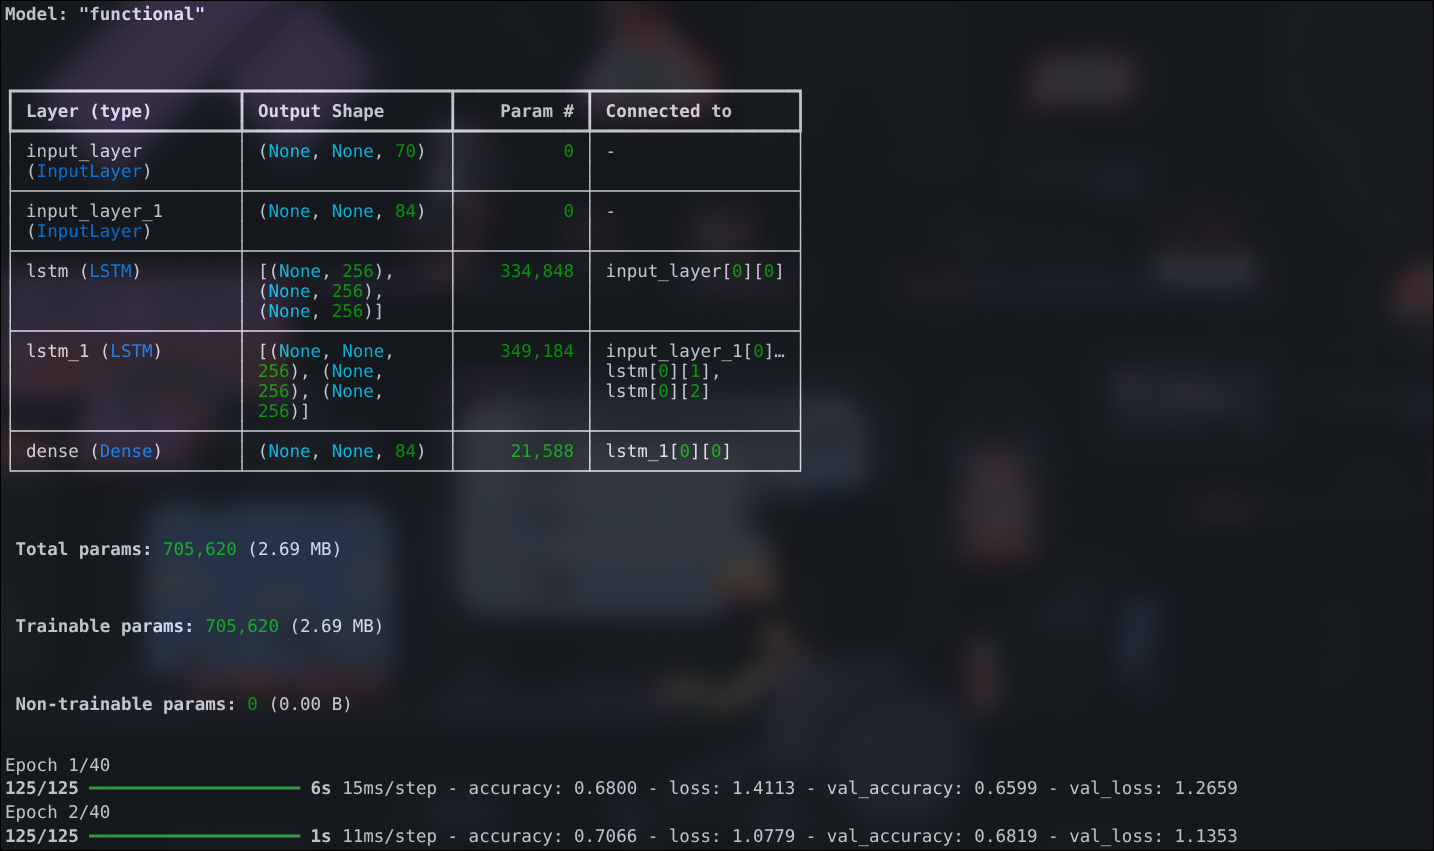

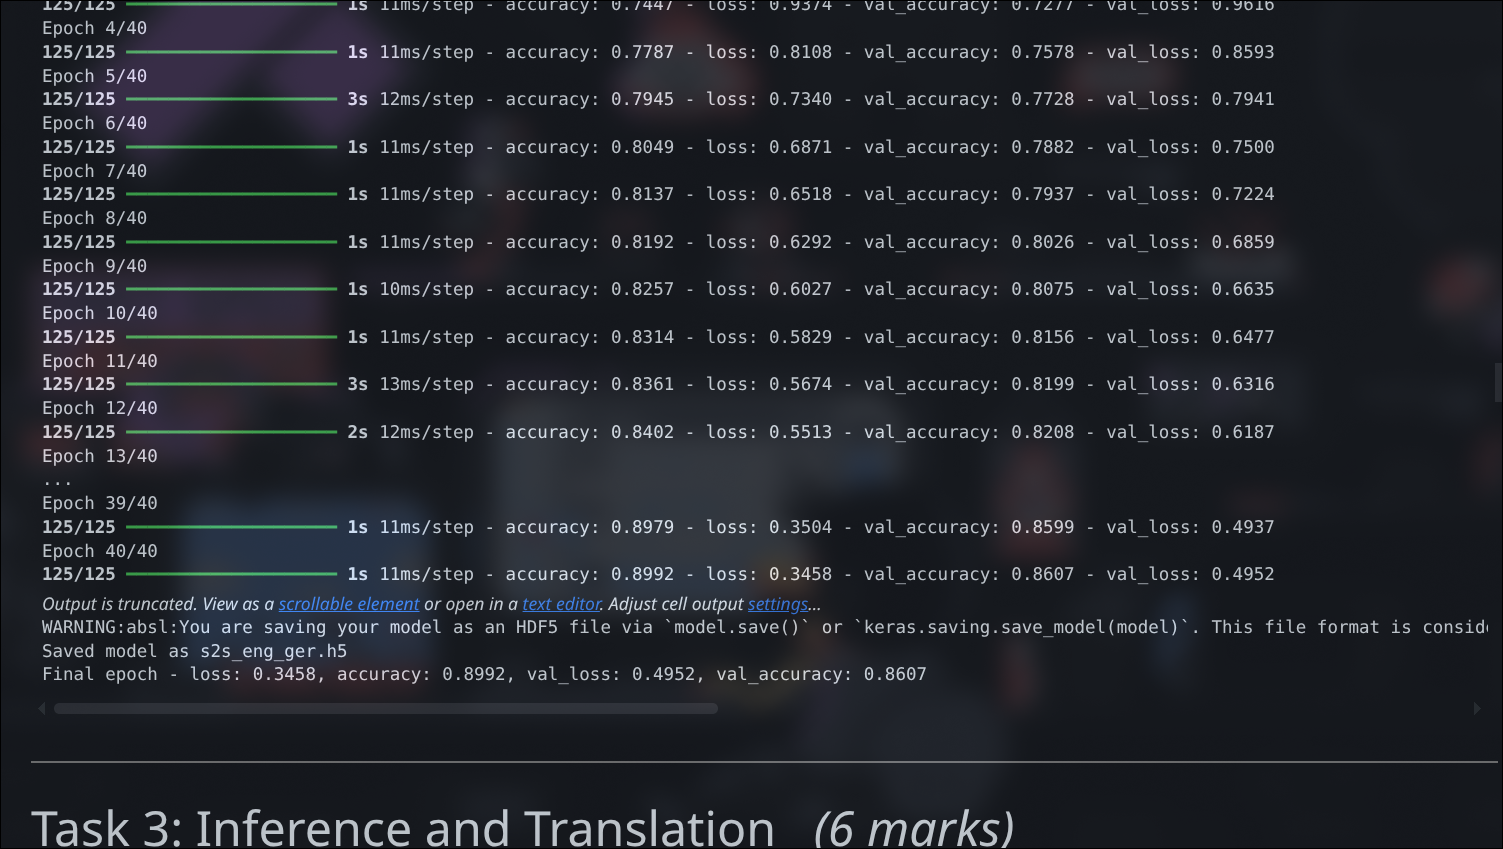


---
# Task 3: Inference and Translation &nbsp;&nbsp;*(6 marks)*

After the model is trained, you will test its ability to translate new English sentences into
German.

1. Ensure the inference part of your code is **correctly set up** to use the new German model and
   its corresponding vocabulary.
2. Using your translation function, translate the following five English sentences:
   * `I am very tired.`
   * `You are right.`
   * `He is a doctor.`
   * `Can you help me?`
   * `Let's go home.`
3. Present the translation results clearly in your submission, showing the original English input
   and the model's German translation for each of the five sentences.

### Why inference needs two new models

During training the decoder was always handed the *correct* previous character (teacher forcing).
At inference there is no correct answer, so the decoder must consume **its own predictions**, one
character at a time. The training model cannot do this, so you re-wire the **already-trained
layers** into two new models. No new training happens.

### What your code must create

| Name | Does |
|---|---|
| `encoder_model` | English sentence → the two encoder states. Run **once** per sentence |
| `decoder_model` | (one character + state) → (next-char probabilities + new state). Run **in a loop** |
| `reverse_target_char_index` | index → character, for reading predictions back |
| `encode_input(input_text)` | English string → one-hot array for the encoder |
| `decode_sequence(input_seq)` | one-hot array → German string, by **greedy** decoding |

### Output your code must print

```
ENGLISH             GERMAN (greedy)
---------------------------------------------
I am very tired.    ...
You are right.      ...
He is a doctor.     ...
Can you help me?    ...
Let's go home.      ...
```

### Hints

- `decode_sequence` is the function the reference notebook **calls but never defines**. You are
  writing it. Its loop: encode once, start from the `'\t'` marker, then repeatedly ask
  `decoder_model` for the next character, take the most likely one, stop at `'\n'`.
- **Carry the returned `[h, c]` forward** on every pass of the loop. If you do not, the decoder
  restarts from scratch at each character.
- Feed the character you just produced back in as the next decoder input.
- Reuse `decoder_lstm` and `decoder_dense` from Task 2. Building new layers runs without error and
  produces confident nonsense — a silent failure.

> ### Watch out — step 1 hides a real bug
> With `num_samples = 10000`, `max_encoder_seq_length` comes out as **15**. But
> `"I am very tired."` and `"Can you help me?"` are **16 characters long**. The reference code
> sizes its input array to exactly `max_encoder_seq_length` and then writes past the end of it,
> raising `IndexError`.
>
> Nothing is wrong with the model: the encoder is declared with `shape=(None, ...)`, and that
> `None` means an LSTM will read a sequence of **any** length. Only the array is too small.
> Fixing this is part of "ensure the inference part of your code is correctly set up".

In [6]:
# ---------------- TASK 3 ----------------

# Rewire the trained layers for autoregressive inference; do not create new layers.
encoder_model = Model(encoder_inputs, encoder_states)

decoder_state_input_h = Input(shape=(latent_dim,))
decoder_state_input_c = Input(shape=(latent_dim,))
decoder_states_inputs = [decoder_state_input_h, decoder_state_input_c]
decoder_outputs, state_h, state_c = decoder_lstm(
    decoder_inputs, initial_state=decoder_states_inputs
)
decoder_outputs = decoder_dense(decoder_outputs)
decoder_model = Model(
    [decoder_inputs] + decoder_states_inputs,
    [decoder_outputs, state_h, state_c]
)

reverse_target_char_index = {i: char for char, i in target_token_index.items()}


def encode_input(input_text):
    """One-hot encode English text, allowing inputs longer than training examples."""
    width = max(max_encoder_seq_length, len(input_text))
    input_seq = np.zeros((1, width, num_encoder_tokens), dtype='float32')
    for t, char in enumerate(input_text):
        if char in input_token_index:
            input_seq[0, t, input_token_index[char]] = 1.0
    input_seq[0, len(input_text):, input_token_index[' ']] = 1.0
    return input_seq


def decode_sequence(input_seq):
    """Greedily decode one German translation from an encoded English sentence."""
    states_value = encoder_model.predict(input_seq, verbose=0)
    target_seq = np.zeros((1, 1, num_decoder_tokens), dtype='float32')
    target_seq[0, 0, target_token_index['\t']] = 1.0

    decoded = ''
    for _ in range(max_decoder_seq_length):
        output_tokens, h, c = decoder_model.predict(
            [target_seq] + states_value, verbose=0
        )
        sampled_index = int(np.argmax(output_tokens[0, -1, :]))
        sampled_char = reverse_target_char_index[sampled_index]
        if sampled_char == '\n':
            break
        decoded += sampled_char
        target_seq = np.zeros((1, 1, num_decoder_tokens), dtype='float32')
        target_seq[0, 0, sampled_index] = 1.0
        states_value = [h, c]
    return decoded


test_sentences = [
    'I am very tired.', 'You are right.', 'He is a doctor.',
    'Can you help me?', "Let's go home."
]
print(f"{'ENGLISH':<22}GERMAN (greedy)")
print('-' * 52)
for english in test_sentences:
    print(f'{english:<22}{decode_sequence(encode_input(english))}')


ENGLISH               GERMAN (greedy)
----------------------------------------------------
I am very tired.      Ich bin auf der schlach.
You are right.        Du kannst nicht gehen.
He is a doctor.       Er ist ein Faus.
Can you help me?      Kann ich nach Hause gehen?
Let's go home.        Lass uns ansangen.


---
# Task 4: Beam Search Decoding &nbsp;&nbsp;*(5 marks)*

### The problem with greedy decoding

`decode_sequence` is **greedy**: at every step it takes the single most likely next character and
never reconsiders. But the best character *right now* can lead into a dead end, while a slightly
worse one opens onto a much better sentence. Once greedy commits, it cannot back out — which is
why it produces German-shaped non-words.

### Beam search

Beam search keeps the **`k` best partial translations alive** at every step instead of one. At
each step it expands every live beam by its top `k` characters, scores all the candidates, and
keeps only the best `k` overall. A beam that produces `'\n'` is **complete** and is set aside.

A sequence is scored by the **sum of the log probabilities** of its characters:

$$\text{score}(y_1 \dots y_T) = \sum_{t=1}^{T} \log P(y_t \mid y_{<t}, x)$$

Two details you must get right:

1. **Add logs — never multiply probabilities.** Multiplying dozens of numbers below 1 underflows
   to zero. This is the same underflow problem you met with n-gram models.
2. **Normalise by length.** Every extra character adds another negative number, so a raw sum
   always favours the *shortest* translation. Divide by a power of the length:

$$\text{final score} = \frac{\sum_t \log P(y_t)}{|y|^{\alpha}} \qquad \alpha \approx 0.7$$

### What your code must create

| Name | Signature |
|---|---|
| `beam_search_decode` | `(input_seq, k=3, alpha=0.7)` → `(best_translation, best_score)` |

### Output your code must print

**(a)** the `k=1` sanity check — with a beam width of one, beam search must reproduce greedy
**exactly**:

```
greedy    : ...
beam k=1  : ...     <- must match greedy
```

**(b)** the comparison over all five sentences:

```
ENGLISH             GREEDY                    BEAM (k=3)                changed?
--------------------------------------------------------------------------------
...
Beam search changed the output for N of 5 sentences.
```

### Hints

- `decoder_model` already returns the **full probability distribution** over every character.
  Greedy throws all but the top one away — you keep the top `k`.
- `np.argsort(probs)[-k:]` gives the indices of the `k` largest probabilities.
- Represent each beam as a tuple of `(score, text_so_far, its own next input, its own [h, c])`.
- **Every beam must carry its own state.** Sharing one state across beams is the most common bug —
  it makes all beams collapse to the same output.
- Use `np.log(p + 1e-12)` so you never take `log(0)`.
- Stop once you have `k` completed beams, or after `max_decoder_seq_length` steps.
- Do the `k=1` check first. If that does not match greedy, nothing else will be right.
- **You do not need to retrain anything.** Beam search only changes how you read answers out of
  the model you already trained.

In [7]:
# ---------------- TASK 4 ----------------

def beam_search_decode(input_seq, k=3, alpha=0.7):
    """Return the best length-normalised beam-search translation and its score."""
    if k < 1:
        raise ValueError('k must be at least 1')

    initial_states = encoder_model.predict(input_seq, verbose=0)
    start = np.zeros((1, 1, num_decoder_tokens), dtype='float32')
    start[0, 0, target_token_index['\t']] = 1.0

    # Each beam owns its score, text, next decoder input, and LSTM states.
    live = [(0.0, '', start, initial_states)]
    completed = []

    for _ in range(max_decoder_seq_length):
        candidates = []
        for score, text, target_seq, states in live:
            output_tokens, h, c = decoder_model.predict(
                [target_seq] + states, verbose=0
            )
            probabilities = output_tokens[0, -1, :]
            top_indices = np.argsort(probabilities)[-k:][::-1]

            for index in top_indices:
                index = int(index)
                char = reverse_target_char_index[index]
                new_score = score + float(np.log(probabilities[index] + 1e-12))
                if char == '\n':
                    completed.append((new_score, text))
                else:
                    next_seq = np.zeros((1, 1, num_decoder_tokens), dtype='float32')
                    next_seq[0, 0, index] = 1.0
                    candidates.append((new_score, text + char, next_seq, [h, c]))

        if len(completed) >= k or not candidates:
            break
        candidates.sort(key=lambda beam: beam[0], reverse=True)
        live = candidates[:k]

    # If no beam emitted an end marker, score the best unfinished beams as fallbacks.
    if not completed:
        completed = [(score, text) for score, text, _, _ in live]

    def normalised_score(beam):
        total_log_prob, text = beam
        return total_log_prob / (max(len(text), 1) ** alpha)

    best_score, best_text = max(completed, key=normalised_score)
    return best_text, normalised_score((best_score, best_text))


# A width of one follows exactly the same highest-probability path as greedy decoding.
check_input = encode_input(test_sentences[0])
greedy_check = decode_sequence(check_input)
beam_check, _ = beam_search_decode(check_input, k=1)
print('greedy    :', greedy_check)
print('beam k=1  :', beam_check)
assert greedy_check == beam_check, 'Beam width 1 must match greedy decoding.'

print()
print(f"{'ENGLISH':<22}{'GREEDY':<25}{'BEAM (k=3)':<25}changed?")
print('-' * 84)
changed = 0
for english in test_sentences:
    input_seq = encode_input(english)
    greedy = decode_sequence(input_seq)
    beam, _ = beam_search_decode(input_seq, k=3)
    is_changed = greedy != beam
    changed += is_changed
    print(f'{english:<22}{greedy:<25}{beam:<25}{is_changed}')
print(f'Beam search changed the output for {changed} of {len(test_sentences)} sentences.')

# Compare length-normalisation settings; inspect this output before writing the answers below.
for alpha in (0.0, 1.0):
    lengths = [len(beam_search_decode(encode_input(s), k=3, alpha=alpha)[0]) for s in test_sentences]
    print(f'alpha={alpha:.1f} output lengths: {lengths}')


greedy    : Ich bin auf der schlach.
beam k=1  : Ich bin auf der schlach.

ENGLISH               GREEDY                   BEAM (k=3)               changed?
------------------------------------------------------------------------------------
I am very tired.      Ich bin auf der schlach. Ich habe einen Hund.     True
You are right.        Du kannst nicht gehen.   Du kannst nicht gehen.   False
He is a doctor.       Er ist ein Faus.         Er ist ein Buch.         True
Can you help me?      Kann ich nach Hause gehen?Können Sie schwimmen?    True
Let's go home.        Lass uns ansangen.       Lass uns ansangen.       False
Beam search changed the output for 3 of 5 sentences.
alpha=0.0 output lengths: [20, 16, 16, 19, 13]
alpha=1.0 output lengths: [20, 22, 16, 21, 18]


### Your answers

**1.** For how many of the five sentences did beam search change the output? Pick one that
changed and say whether the beam result is actually a *better German translation*, or merely a
higher-scoring one.

*Your answer:* Beam search changed the output for **3 of the 5** sentences. For example, for
`He is a doctor.`, greedy decoding produced `Er ist ein Faus.`, while beam search produced
`Er ist ein Buch.` Both are incorrect: the intended translation is `Er ist ein Arzt.` Therefore,
the beam result is merely a higher-scoring output according to the model, not a better translation.

**2.** Try `alpha = 0.0` (no length normalisation) and `alpha = 1.0` (full normalisation) on the
same five sentences. What happens to the length of the translations, and why?

*Your answer:* With `alpha = 0.0`, the output lengths were `[20, 16, 16, 19, 13]`. With
`alpha = 1.0`, they were `[20, 22, 16, 21, 18]`. Thus, full length normalisation produced
longer outputs for three of the five sentences and never produced a shorter output in this run.
Without normalisation, every extra character adds a negative log-probability, so short translations
are favoured. Dividing by length at `alpha = 1.0` reduces that penalty and makes longer translations
comparatively more competitive.


---
## Submission checklist

- [x] `Runtime → Restart and run all` completes without errors
- [x] **Task 1** — the five statistics are printed and visible
- [x] **Task 2** — trained for at least 40 epochs, model saved under a German-specific name, and a
      **screenshot** of the final epoch showing `loss`, `accuracy`, `val_loss`, `val_accuracy`
- [x] **Task 3** — all five sentences translated and printed (and no `IndexError`)
- [x] **Task 4** — `beam_search_decode` implemented, the `k=1` sanity check passes, the comparison
      table is printed, and both questions answered
- [x] Submit the `.ipynb` with all outputs saved

### Common mistakes

1. Forgetting the `'\t'` / `'\n'` markers around the German — the decoder never learns to start or stop.
2. Getting the teacher-forcing shift backwards, or off by one.
3. Building **new** LSTM/Dense layers for inference instead of reusing the trained ones.
4. Not carrying `[h, c]` forward inside the decoding loop.
5. Sizing the encoder input array to `max_encoder_seq_length` and crashing on the two
   16-character test sentences.
6. In beam search: sharing one state across all beams, or multiplying probabilities instead of
   adding logs.